In [1]:
# Carregar os CSVs limpos de todas as vacas
import pandas as pd
from pathlib import Path

# 1. Carregar e juntar os CSVs limpos de todas as vacas
files = sorted(Path("./dados/clean").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(f).assign(source_file=f.name) for f in files),
    ignore_index=True,
)


In [2]:
# Estilo dos gráficos; treinamos com 8 vacas e testamos em T09 e T10 (vacas que o modelo não viu), usando as janelas vizinhas como contexto
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Escolher o estilo dos gráficos e criar a pasta onde as figuras serão salvas
sns.set_theme(style="whitegrid")
Path("figuras").mkdir(exist_ok=True)

# 2. Definir a ordem dos comportamentos nos gráficos (7 = deitada, 2 = em pé/andando, 3 = alimentação)
ordem = ["Deitada", "Em pé/andando", "Alimentação"]

# 3. Converter o comportamento para inteiro (o df já foi carregado acima)
df["behavior"] = df["behavior"].astype(int)

In [3]:
# Ordenar as janelas por tempo em cada vaca e separar treino (8 vacas) e teste (T09 e T10)
# 1. Ordenar por vaca e por tempo
df = df.sort_values(["vaca_id", "janela"]).reset_index(drop=True)

# 2. Separar os 16 atributos originais, o comportamento (y) e a vaca de cada janela
colunas_base = [c for c in df.columns if c.split("_")[0] in ("x", "y", "z", "mag")]
X_base = df[colunas_base]
y = df["behavior"]
vaca_id = df["vaca_id"]

# 3. Escolher as 2 vacas de teste (as outras 8 vacas serão usadas no treino)
vacas_teste = ["T09", "T10"]
eh_teste = vaca_id.isin(vacas_teste)

print(f"{X_base.shape[1]} atributos originais")
print(f"Treino: {(~eh_teste).sum()} janelas de 8 vacas")
print(f"Teste: {eh_teste.sum()} janelas das vacas {vacas_teste}")

16 atributos originais
Treino: 56995 janelas de 8 vacas
Teste: 14249 janelas das vacas ['T09', 'T10']


In [4]:
# Atributos de contexto: médias e desvios das janelas vizinhas da mesma vaca (NaN na primeira e na última janela)
# 1. Escolher os atributos que serão copiados das janelas vizinhas
colunas_contexto = ["x_mean", "y_mean", "z_mean", "mag_mean", "x_std", "y_std", "z_std", "mag_std"]
por_vaca = df.groupby("vaca_id")[colunas_contexto]

# 2. Criar as colunas das janelas anteriores (antes1 = 10 s antes, antes2 = 20 s antes)
antes_1 = por_vaca.shift(1).add_suffix("_antes1")
antes_2 = por_vaca.shift(2).add_suffix("_antes2")

# 3. Criar as colunas das janelas seguintes
depois_1 = por_vaca.shift(-1).add_suffix("_depois1")
depois_2 = por_vaca.shift(-2).add_suffix("_depois2")

# 4. Montar a tabela de atributos com os dois lados
X_dois_lados = pd.concat([X_base, antes_1, antes_2, depois_1, depois_2], axis=1)

print(f"Atributos originais: {X_base.shape[1]}")
print(f"Com os dois lados: {X_dois_lados.shape[1]}")

Atributos originais: 16
Com os dois lados: 48


In [5]:
# Função que treina nas vacas de treino e avalia nas de teste
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

y_teste = y[eh_teste]


def avaliar(modelo, X):
    # 1. Treinar com as 8 vacas de treino
    modelo.fit(X[~eh_teste], y[~eh_teste])

    # 2. Prever o comportamento das 2 vacas de teste
    previsoes = modelo.predict(X[eh_teste])

    # 3. Calcular a acurácia e o F1 macro
    acuracia = accuracy_score(y_teste, previsoes)
    f1 = f1_score(y_teste, previsoes, average="macro")
    return acuracia, f1, previsoes


# Modelo usado nos experimentos (class_weight balanced compensa o desbalanceamento das classes)
random_forest = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)


In [6]:
# Experimentos
# Experimento 1: chute (sempre prever a classe mais comum, "deitada")
acuracia_chute = (y_teste == 7).mean()
f1_chute = f1_score(y_teste, [7] * len(y_teste), average="macro", zero_division=0)
print(f"Chute: acurácia {acuracia_chute:.3f} | F1 macro {f1_chute:.3f}")

Chute: acurácia 0.536 | F1 macro 0.233


In [7]:
# Experimento 2: Random Forest com os 16 atributos originais
acc_original, f1_original, prev_original = avaliar(random_forest, X_base)
print(f"RF original: acurácia {acc_original:.3f} | F1 macro {f1_original:.3f}")

RF original: acurácia 0.814 | F1 macro 0.790


In [8]:
# Experimento 4: Random Forest com os dois lados (janelas t-2, t-1, t+1 e t+2)
acc_dois_lados, f1_dois_lados, prev_dois_lados = avaliar(random_forest, X_dois_lados)
print(f"RF + dois lados: acurácia {acc_dois_lados:.3f} | F1 macro {f1_dois_lados:.3f}")

RF + dois lados: acurácia 0.870 | F1 macro 0.857


In [9]:
# Comparação: o contexto das janelas vizinhas é o que mais melhora o modelo; o "dois lados" usa janelas futuras e só serve para dados já gravados
# 1. Juntar os resultados numa tabela
tabela = pd.DataFrame(
    {
        "Acurácia": [acuracia_chute, acc_original, acc_dois_lados],
        "F1 macro": [f1_chute, f1_original, f1_dois_lados],
    },
    index=["Chute (sempre deitada)", "RF original", "RF + dois lados"],
)

# 2. Salvar a tabela e exibir
tabela.round(3).to_csv("figuras/tabela_comparacao_modelos.csv")
tabela.round(3)

,Acurácia,F1 macro
Chute (sempre deitada),0.536,0.233
RF original,0.814,0.790
RF + dois lados,0.870,0.857


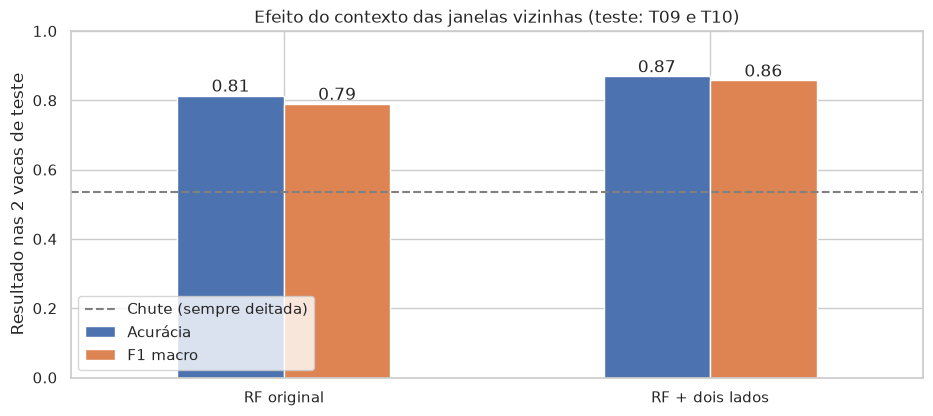

In [10]:
# 1. Separar o chute dos modelos (o chute vira uma linha tracejada)
modelos = tabela.drop(index="Chute (sempre deitada)")

# 2. Plotar barras de acurácia e F1 macro de cada experimento
ax = modelos.plot(kind="bar", figsize=(11, 4.5))
ax.axhline(acuracia_chute, color="gray", linestyle="--", label="Chute (sempre deitada)")

# 3. Escrever o valor em cima de cada barra
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f")

plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.title("Efeito do contexto das janelas vizinhas (teste: T09 e T10)")
plt.ylabel("Resultado nas 2 vacas de teste")
plt.legend()
plt.savefig("figuras/05_comparacao_experimentos.png", bbox_inches="tight")
plt.show()

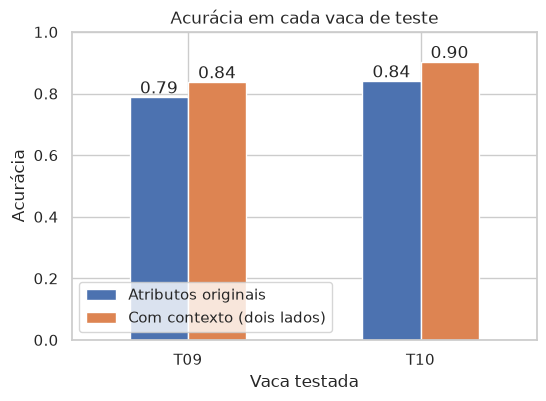

In [11]:
# Acurácia em cada vaca de teste
# 1. Calcular a acurácia de cada vaca de teste, com os atributos originais e com o contexto
vaca_teste = vaca_id[eh_teste].values
acc_por_vaca = {"Atributos originais": [], "Com contexto (dois lados)": []}
for vaca in vacas_teste:
    linhas = vaca_teste == vaca
    acc_por_vaca["Atributos originais"].append(accuracy_score(y_teste[linhas], prev_original[linhas]))
    acc_por_vaca["Com contexto (dois lados)"].append(accuracy_score(y_teste[linhas], prev_dois_lados[linhas]))
comparacao = pd.DataFrame(acc_por_vaca, index=vacas_teste)

# 2. Plotar as barras lado a lado
comparacao.plot(kind="bar", figsize=(6, 4))
for barras in plt.gca().containers:
    plt.gca().bar_label(barras, fmt="%.2f")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.title("Acurácia em cada vaca de teste")
plt.xlabel("Vaca testada")
plt.ylabel("Acurácia")
plt.legend()
plt.savefig("figuras/06_acuracia_por_vaca.png", bbox_inches="tight")
plt.show()

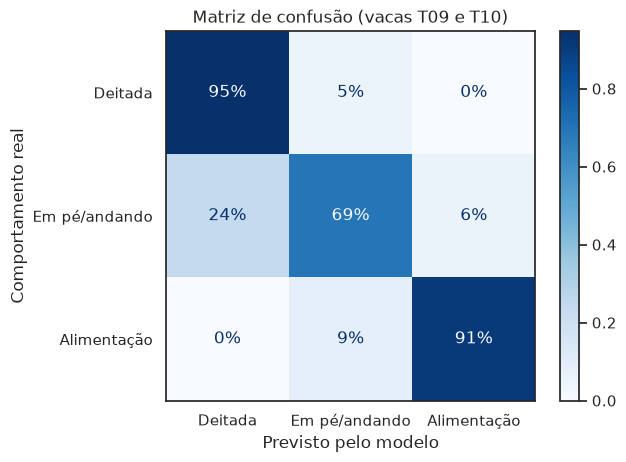

               precision    recall  f1-score   support

      Deitada      0.880     0.948     0.913      7636
Em pé/andando      0.820     0.694     0.752      4043
  Alimentação      0.902     0.913     0.907      2570

     accuracy                          0.870     14249
    macro avg      0.867     0.852     0.857     14249
 weighted avg      0.867     0.870     0.866     14249



In [12]:
# Matriz de confusão: cada linha é o comportamento real e cada coluna o previsto
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Plotar a matriz de confusão (cada linha soma 100% da classe real)
with sns.axes_style("white"):  # estilo sem grade, o whitegrid desenhava linhas sobre os quadrados
    disp = ConfusionMatrixDisplay.from_predictions(
        y_teste, prev_dois_lados, labels=[7, 2, 3], display_labels=ordem,
        normalize="true", cmap="Blues", values_format=".0%",
    )
disp.ax_.grid(False)
disp.figure_.axes[-1].grid(False)  # barra de cores
plt.title("Matriz de confusão (vacas T09 e T10)")
plt.xlabel("Previsto pelo modelo")
plt.ylabel("Comportamento real")
plt.savefig("figuras/07_matriz_confusao.png", bbox_inches="tight")
plt.show()

# 2. Exibir precisão, recall e F1 de cada classe
print(classification_report(y_teste, prev_dois_lados, labels=[7, 2, 3], target_names=ordem, digits=3))

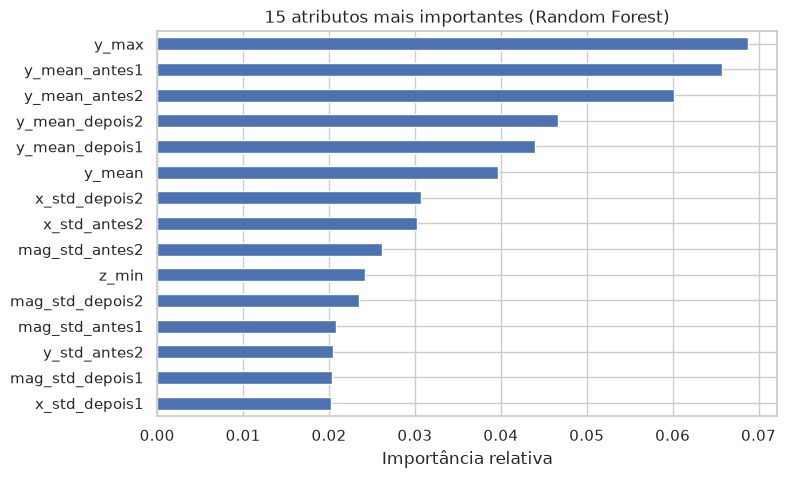

In [13]:
# Atributos mais importantes: os sufixos antes/depois indicam a janela vizinha (ex.: y_mean_antes1 é a média de y 10 s antes)
# 1. Treinar o Random Forest com as 8 vacas de treino (só para olhar a importância dos atributos)
modelo_final = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)
modelo_final.fit(X_dois_lados[~eh_teste], y[~eh_teste])

# 2. Pegar os 15 atributos mais importantes
importancia = pd.Series(modelo_final.feature_importances_, index=X_dois_lados.columns)
top_15 = importancia.sort_values().tail(15)

# 3. Plotar as barras
top_15.plot(kind="barh", figsize=(8, 5))
plt.title("15 atributos mais importantes (Random Forest)")
plt.xlabel("Importância relativa")
plt.savefig("figuras/08_importancia_atributos.png", bbox_inches="tight")
plt.show()

## Conclusão

**Resultado.** Treinando com 8 vacas e testando em 2 vacas que o modelo nunca viu (T09 e T10), o Random Forest chegou a **87% de acurácia** (F1 macro 0,86). Sempre chutar "deitada" acertaria só 54%.

**Por que separar por vaca.** Em uma divisão aleatória das janelas, janelas vizinhas da mesma vaca cairiam no treino e no teste, e o resultado seria otimista. Testar em vacas não vistas dá uma avaliação mais honesta.

**O que mais ajudou.** Usar as janelas vizinhas como contexto (algoritmo: Random Forest, com `class_weight="balanced"`):

| Modelo | Acurácia |
|---|---|
| Chute (sempre deitada) | 54% |
| Random Forest, 16 atributos originais | 81% |
| Random Forest + dois lados (2 antes e 2 depois) | 87% |

**Onde o modelo erra.** Deitada (95%) e alimentação (91%) são bem reconhecidas. **Em pé/andando é a mais difícil (69%)**, e 24% dessas janelas são confundidas com deitada.

**Limitações.**
- O teste usa só 2 vacas, então o 87% pode variar com outras vacas.
- A versão "dois lados" usa janelas futuras, então só serve para dados já gravados, não para monitoramento em tempo real.